# Solver comparison

## Do the solvers find the best energy, and how does that change when the network gets bigger?

Gurobi is exact, so its energy is the reference. SA and QAOA are compared against it.

In [ ]:
import os, sys
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")          
sys.path.append(".")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.utils import load_all_solutions
from src.metrics import success_rate

sol = load_all_solutions()
sol["junctions"] = [p["n_junctions"] for p in sol["params"]]

networks = ["Net1", "Net2", "Net3"]
qubos = ["topological", "leak"]
solvers = ["gurobi", "sa", "qaoa"]      # qaoa is drawn once its solutions are saved
colors = {"gurobi": "black", "sa": "tab:blue", "qaoa": "tab:orange"}

# how many solutions we have
sol.groupby(["network", "solver"]).size().unstack(fill_value=0)

solver,gurobi,sa
network,,
Net1,10,10
Net2,10,10
Net3,10,10


## 1. How far is each solver from the best energy?

### - **gap**: solver energy minus Gurobi energy (0 means it found the optimum)
### - **success %**: share of the solver's runs that reached the optimum

In [2]:
best = sol[sol.solver == "gurobi"].set_index(["network", "formulation", "k"])["energy"]
sol["best"] = [best[(n, f, k)] for n, f, k in zip(sol.network, sol.formulation, sol.k)]
sol["gap"] = (sol["energy"] - sol["best"]).round(6)
sol["success %"] = [100 * success_rate(e, b) if e else np.nan for e, b in zip(sol.sample_energies, sol.best)]

others = sol[sol.solver != "gurobi"]
others.pivot_table(index=["formulation", "solver", "network"], columns="k", values="gap").round(2)

k                            1     2    3    4     5    6    8     10    15  \
formulation solver network                                                    
leak        sa     Net1     0.0  0.00  0.0  0.0  0.00  NaN  NaN   NaN   NaN   
                   Net2     NaN  0.00  NaN  0.0   NaN  0.0  0.0  0.00   NaN   
                   Net3     NaN  0.03  NaN  NaN  0.13  NaN  NaN  0.05  0.22   
topological sa     Net1     0.0  0.00  0.0  0.0  0.00  NaN  NaN   NaN   NaN   
                   Net2     NaN  0.00  NaN  0.0   NaN  0.0  0.0  0.61   NaN   
                   Net3     NaN  0.00  NaN  NaN  0.01  NaN  NaN  0.40  1.40   

k                             20  
formulation solver network        
leak        sa     Net1      NaN  
                   Net2      NaN  
                   Net3     0.33  
topological sa     Net1      NaN  
                   Net2      NaN  
                   Net3     1.65

## 2. Energy for each number of sensors

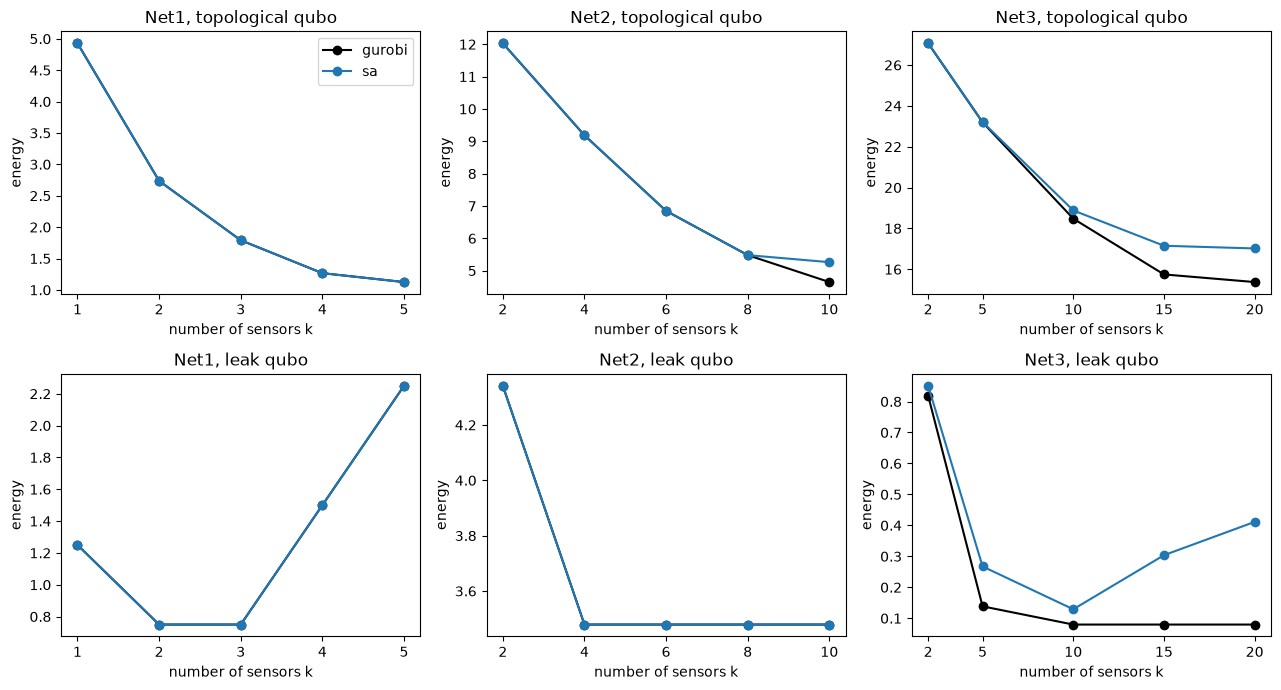

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for row, qubo in enumerate(qubos):
    for col, network in enumerate(networks):
        ax = axes[row, col]
        for solver in solvers:
            d = sol[(sol.formulation == qubo) & (sol.network == network) & (sol.solver == solver)].sort_values("k")
            if len(d):
                ax.plot(d["k"], d["energy"], marker="o", color=colors[solver], label=solver)
        ax.set_xticks(sorted(sol[sol.network == network]["k"].unique()))
        ax.set_title(f"{network}, {qubo} qubo")
        ax.set_xlabel("number of sensors k")
        ax.set_ylabel("energy")
axes[0, 0].legend()
plt.tight_layout()

## 3. Repeat SA with 10 different seeds

One trial = one network, one QUBO, one k and one seed. In each trial SA does 100 runs and we keep its best valid placement.

In [6]:
from src.qubo import build_Q_topological, build_Q_leak, pick_penalty, energy
from src.solvers import solve_gurobi, solve_sa

builders = {"topological": build_Q_topological, "leak": build_Q_leak}
budgets = {"Net1": [1, 2, 3, 4, 5], "Net2": [2, 4, 6, 8, 10], "Net3": [2, 5, 10, 15, 20]}


def sa_gap(network, qubo, k, seed, num_sweeps=1000):
    """run sa once (100 runs inside) and return the gap of its best valid placement to gurobi."""
    build = builders[qubo]
    Q0, const0, _ = build(network, k, penalty=0)
    best = solve_gurobi(Q0, const0, k=k)[1]
    Q, const, _ = build(network, k, pick_penalty(Q0))
    samples = solve_sa(Q, const, num_sweeps=num_sweeps, seed=seed)[3]
    valid = [s for s in samples if sum(s) == k]
    return min(energy(Q0, const0, s) for s in valid) - best

In [7]:
rows = []
for network in networks:
    for qubo in qubos:
        for k in budgets[network]:
            for seed in range(10):
                rows.append({"network": network, "qubo": qubo, "k": k, "seed": seed,
                             "gap": sa_gap(network, qubo, k, seed)})
seeds = pd.DataFrame(rows)
seeds["found optimum"] = seeds["gap"] < 1e-6

Restricted license - for non-production use only - expires 2028-11-29


qubo,topological,leak
network,,
Net1,100.0,100.0
Net2,72.0,100.0
Net3,38.0,16.0


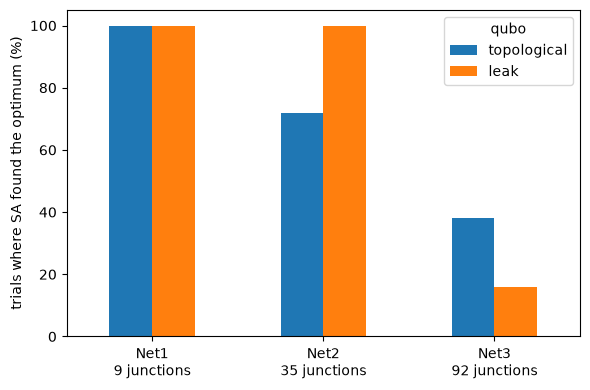

In [8]:
found = 100 * seeds.groupby(["network", "qubo"])["found optimum"].mean().unstack()[qubos]
display(found)

ax = found.plot.bar(figsize=(6, 4), rot=0, color=["tab:blue", "tab:orange"])
ax.set_xticklabels(["Net1\n9 junctions", "Net2\n35 junctions", "Net3\n92 junctions"])
ax.set_xlabel("")
ax.set_ylabel("trials where SA found the optimum (%)")
ax.legend(title="qubo")
plt.tight_layout()

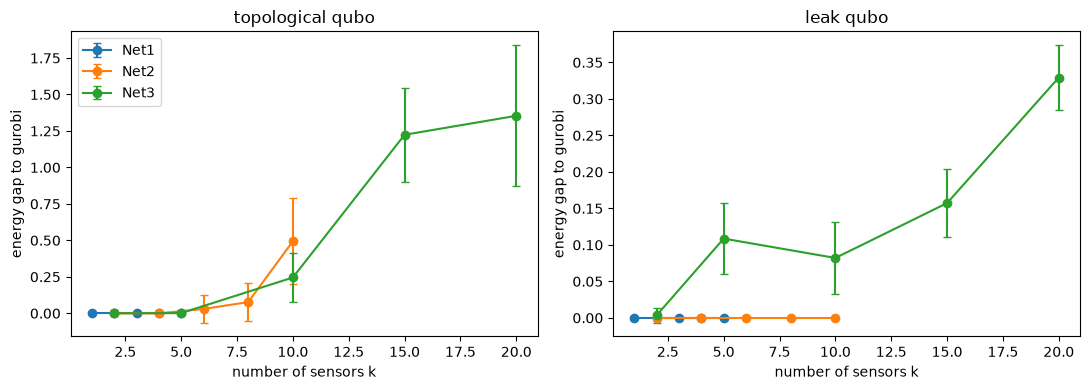

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, qubo in zip(axes, qubos):
    for network in networks:
        d = seeds[(seeds.qubo == qubo) & (seeds.network == network)].groupby("k")["gap"].agg(["mean", "std"])
        ax.errorbar(d.index, d["mean"], yerr=d["std"], marker="o", capsize=3, label=network)
    ax.set_title(f"{qubo} qubo")
    ax.set_xlabel("number of sensors k")
    ax.set_ylabel("energy gap to gurobi")
axes[0].legend()
plt.tight_layout()

## 4. Does SA catch up if we give it more steps?

Net3 only, with 100, 1,000 (our default) and 10,000 steps per run, 5 seeds each.

In [11]:
rows = []
for qubo in qubos:
    for k in [10, 20]:
        for num_sweeps in [100, 1000, 10000]:
            for seed in range(5):
                rows.append({"qubo": qubo, "k": k, "steps": num_sweeps, "seed": seed,
                             "gap": sa_gap("Net3", qubo, k, seed, num_sweeps)})
effort = pd.DataFrame(rows)
effort.groupby(["qubo", "k", "steps"])["gap"].mean().unstack().round(2)

steps           100    1000   10000
qubo        k                      
leak        10   0.10   0.07   0.05
            20   0.46   0.32   0.21
topological 10   0.82   0.20   0.04
            20   2.60   1.44   0.91

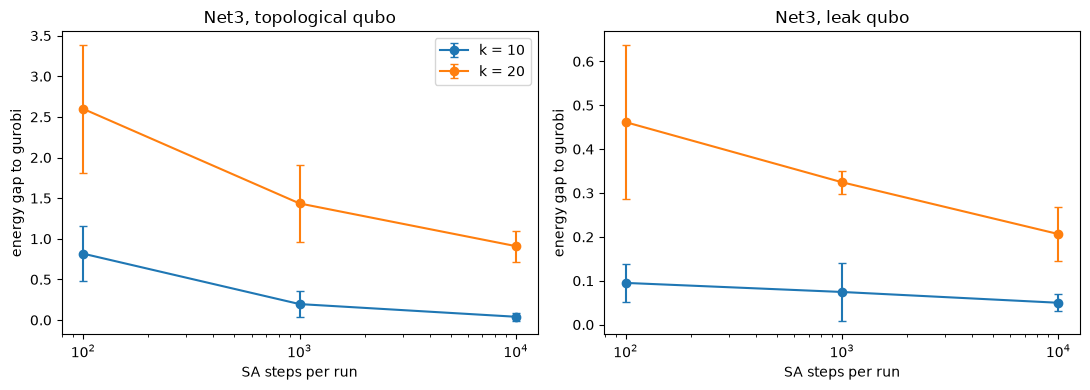

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, qubo in zip(axes, qubos):
    for k in [10, 20]:
        d = effort[(effort.qubo == qubo) & (effort.k == k)].groupby("steps")["gap"].agg(["mean", "std"])
        ax.errorbar(d.index, d["mean"], yerr=d["std"], marker="o", capsize=3, label=f"k = {k}")
    ax.set_xscale("log")
    ax.set_title(f"Net3, {qubo} qubo")
    ax.set_xlabel("SA steps per run")
    ax.set_ylabel("energy gap to gurobi")
axes[0].legend()
plt.tight_layout()

## Conclusion

- **Small networks:** SA always finds the Gurobi optimum on Net1 (9 junctions).
- **Larger networks:** SA becomes unreliable. On Net3 (92 junctions) it finds the optimum in 38% (topological) and 16% (leak) of trials.
- **Budget matters too:** on Net3 the gap grows with k, because the number of possible placements grows very fast.
- **More SA steps help but do not close the gap:** at k = 20, 100x more steps reduce the gap from 2.6 to 0.9.

**QAOA:** _to be added once the results are saved (Net1 only)._

In [13]:
size = pd.DataFrame({"variables": sol.groupby("network")["junctions"].first()})
size["pair terms"] = size["variables"] * (size["variables"] - 1) // 2
for solver in ["gurobi", "sa"]:
    size[f"{solver} time (s)"] = sol[sol.solver == solver].groupby("network")["runtime_s"].mean().round(3)
size

,variables,pair terms,gurobi time (s),sa time (s)
network,,,,
Net1,9,36,0.010,0.018
Net2,35,595,0.026,0.097
Net3,92,4186,0.105,0.395


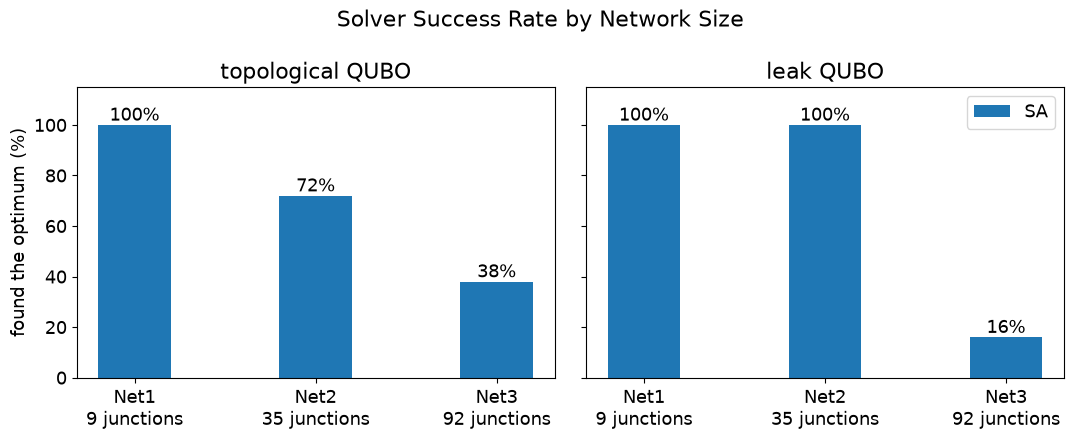

In [15]:
sa_found = 100 * seeds.groupby(["qubo", "network"])["found optimum"].mean()

# qaoa: share of its saved solutions that reached the optimum
qaoa = sol[sol.solver == "qaoa"]
qaoa_found = 100 * (qaoa["gap"] < 1e-6).groupby([qaoa.formulation, qaoa.network]).mean()
shift = 0.2 if len(qaoa) else 0          # INSERT QAOA

plt.rcParams.update({"font.size": 13})
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
x = np.arange(3)
for ax, qubo in zip(axes, qubos):
    bars = ax.bar(x - shift, [sa_found[(qubo, n)] for n in networks], width=0.4, color="tab:blue", label="SA")
    ax.bar_label(bars, fmt="%.0f%%")
    if len(qaoa):
        bars = ax.bar(x + shift, [qaoa_found.get((qubo, n), 0) for n in networks], width=0.4,
                      color="tab:orange", label="QAOA (Net1 only)")
        ax.bar_label(bars, labels=[f"{qaoa_found[(qubo, n)]:.0f}%" if (qubo, n) in qaoa_found else "" for n in networks])
    ax.set_xticks(x)
    ax.set_xticklabels(["Net1\n9 junctions", "Net2\n35 junctions", "Net3\n92 junctions"])
    ax.set_title(f"{qubo} QUBO")
    ax.set_ylim(0, 115)
axes[0].set_ylabel("found the optimum (%)")
axes[1].legend(loc="upper right")
fig.suptitle("Solver Success Rate by Network Size")
plt.tight_layout()

os.makedirs("results/figures", exist_ok=True)
plt.savefig("results/figures/scalability.png", dpi=200)

## Conclusion

- **Small networks:** SA always finds the Gurobi optimum on Net1 (9 junctions).
- **Larger networks:** SA becomes unreliable. On Net3 (92 junctions) it finds the optimum in 38% (topological) and 16% (leak) of trials.
- **Budget matters too:** on Net3 the gap grows with k, because the number of possible placements grows very fast.
- **More SA steps help but do not close the gap:** at k = 20, 100x more steps reduce the gap from 2.6 to 0.9.
- **Time is not the bottleneck:** every run takes under a second.